# Manual GRB251013C model

Generate a single afterglow light-curve model for parameter values you set by hand, plotted against all observed data (XRT + i-band + Leavitt Rc/Ic + 7DT SED).

Companion to `manual_model.py` (same underlying logic, imported below) — use this notebook to tweak values interactively and see the plot inline; use the script for one-off CLI runs or automation.

Run from this directory (`projects/GRB/code/fitting`) with the `yp` kernel.

In [1]:
from pathlib import Path
from datetime import datetime
import json

import matplotlib.pyplot as plt
from IPython.display import Image, display

import grb.modeling
from grb.params import make_param_defs
from grb.prior import ParamDefWithPrior
from grb.plotting import render_light_curve_figure, _posterior_draws
from grb.results import read_labels
from VegasAfterglow import Scale
from manual_model import build_baseline, check_physical_validity

## Model configuration

Pick the circumburst medium, which components are on, and (if `include_flare=True`) the flare profile shape. This determines which parameter names are valid below (e.g. `theta_c_wing` only exists if `include_wing=True`; the flare parameter names depend on `flare_shape` -- see `grb.functions.FLARE_SHAPES`).

In [2]:
environment = "wind"     # "ism", "wind", or "stratified"
include_flare = True
flare_shape = "norris"  # "norris", "sbpl", or "gaussian" (see grb.functions.FLARE_SHAPES); only matters if include_flare=True
include_wing = False
mark_7dt_time = True

param_defs = make_param_defs(include_flare=include_flare, include_wing=include_wing, environment=environment,
                             flare_shape=flare_shape)
# The final early-afterglow MCMC (modeling/early_phase_model.py) frees xi_e / xi_e_r (0.01-1, linear); grb.params
# leaves them out (xi = 1). Added here so they reach make_core_model and the logL cell's theta.
param_defs += [ParamDefWithPrior("xi_e", 0.01, 1.0, Scale.LINEAR), ParamDefWithPrior("xi_e_r", 0.01, 1.0, Scale.LINEAR)]
# Model grid of the final MCMC; the grb default (0.1, 0.25, 10) shifts the FS+RS flux by ~0.1-0.2%.
grb.modeling.MODEL_RESOLUTIONS = (0.3, 1.0, 30.0)
baseline, notes = build_baseline(param_defs)
for note in notes:
    print(f"Note: {note}")

Note: tau_rise_flare: INITIAL_GUESS value 1222.55 outside [1, 1000], clipped to 1000
Note: xi_e: not in INITIAL_GUESS, set to bounds midpoint 0.505
Note: xi_e_r: not in INITIAL_GUESS, set to bounds midpoint 0.505


## Set parameter values

`overrides = {**early_afterglow, **flare}`, so the model is F_total(t) = F_FS+RS(t) + F_flare(t).

- **`early_afterglow`**: the forward and reverse shock values come from the FINAL early-afterglow MCMC posterior (`result/early_phase_FINAL_run1_20261008_220945` + `_run2_20261008_221517`, burn-in removed). They are one real posterior sample, the one closest to the posterior centre, chosen by `modeling/extract_representative_manual_model.py`. Do not replace individual values with marginal medians: the parameters are strongly correlated, so a mixed set need not lie in the posterior. To compare, swap the whole dict for the `early_afterglow` in `map_overrides.py` or `random_overrides.py` in the same directory. `xi_e` / `xi_e_r` were free in that fit and must be set; the cell stops if they are missing. `tau` is the jet/ejecta duration, not a flare time.
- **`flare`**: the earlier Norris flare fit, unchanged. Note that it was fitted together with the old early-afterglow model.

The `grb.params` prior box differs from the MCMC prior, so `E_iso_core` (> 1e54) and `tau` (> 400 s) print an "outside the prior box" warning. Values are **not** clipped. The wing-jet block is commented out because it only applies when `include_wing=True`. Any override not used by the current config is ignored with a warning.

name                         value   source
E_iso_core              1.8478e+54   override
Gamma0_core                42.9268   override
theta_c_core             0.0175396   override
A_star                     4.42169   override
p                          2.01554   override
eps_e                    0.0031278   override
eps_B                     0.021471   override
tau                        416.357   override
p_r                        2.00991   override
eps_e_r                   0.157236   override
eps_B_r                   0.197164   override
A_V                       0.362179   override
t_start_flare              2149.89   override
tau_rise_flare             150.662   override
tau_decay_flare            5288.29   override
A_flare                9.89646e-10   override
flare_beta                0.751384   override
xi_e                      0.754353   override
xi_e_r                   0.0539356   override


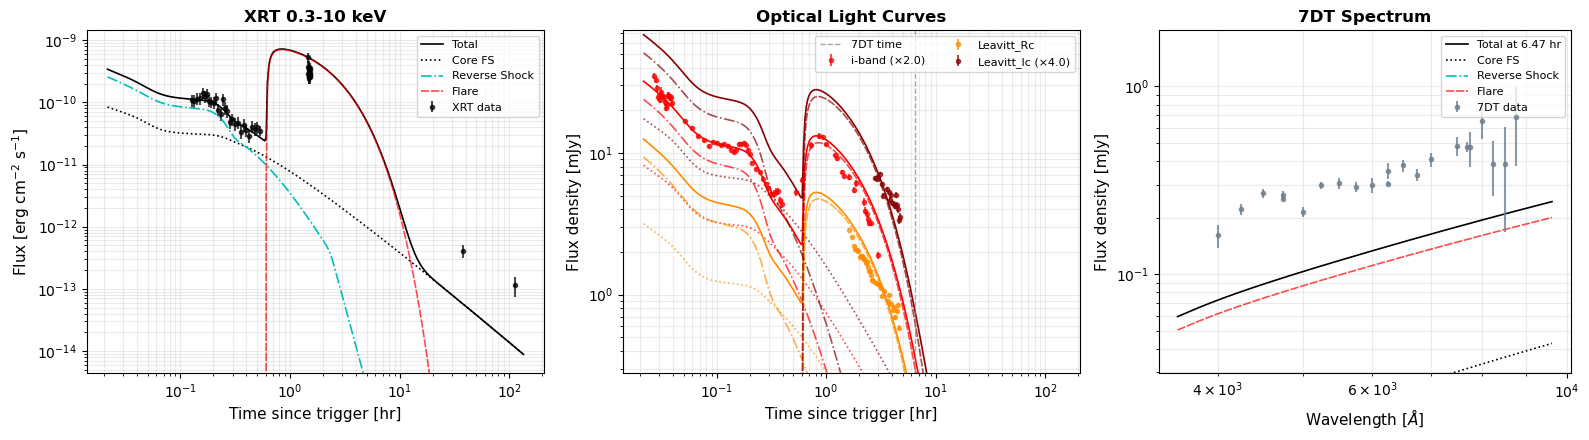

In [15]:
# --- Early afterglow (FS + RS): FINAL MCMC posterior, representative sample ---
# One actual chain state (run2 step 101478 walker 53, log posterior -88.32): the sample
# closest to the posterior median in std-normalised distance. Source: result/early_phase_FINAL_posterior/
# manual_model_overrides/representative_overrides.py (map_overrides.py / random_overrides.py are alternatives).
# Keep these values together -- E_iso-xi_e_r and p_r-eps_e_r are strongly correlated, and the marginal medians
# put together give log posterior -350 instead of ~ -88.
early_afterglow = {
    # --- Core jet ---
    "E_iso_core": 1.84780419338629e+54,
    "Gamma0_core": 42.92684217858337,
    "theta_c_core": 0.017539632661367616,

    # --- Wind environment (environment="wind") ---
    "A_star": 4.421694087558172,

    # --- Forward shock (xi_e free in the fit -- must be given) ---
    "p": 2.015535683988102,
    "eps_e": 0.0031278031404307735,
    "eps_B": 0.02147101842306743,
    "xi_e": 0.7543527915800833,

    # --- Early-afterglow jet/ejecta duration [s] (TophatJet duration; NOT a flare time) ---
    "tau": 416.35727735379555,

    # --- Reverse shock (xi_e_r free in the fit -- must be given) ---
    "p_r": 2.0099091528179067,
    "eps_e_r": 0.15723567719656473,
    "eps_B_r": 0.1971638818411699,
    "xi_e_r": 0.05393560834632512,

    # --- Host extinction ---
    "A_V": 0.36217938684309203,
}

# --- Flare (Norris, matches include_flare=True, flare_shape="norris"; earlier fit, unchanged) ---
flare = {
    "t_start_flare": 2149.89,
    "tau_rise_flare": 150.66236,
    "tau_decay_flare": 5288.29,
    "A_flare": 9.89646e-10,
    "flare_beta": 0.751384,
    # "t_start_flare": 2149.89,
    # "tau_rise_flare": 1.66236,
    # "tau_decay_flare": 5288.29,
    # "A_flare": 4.89646e-10,
    # "flare_beta": 0.721384,
    # --- Flare (flare_shape="sbpl"; not used in this fit -- these are just the fit_final_model.py INITIAL_GUESS seed) ---
    # "t_break_flare": 2300,
    # "alpha_rise_flare": -3,
    # "alpha_decay_flare": 2,
    # "smooth_flare": 1,
    # "A_flare": 9.92559e-10,
    # "flare_beta": 0.820278,

    # --- Flare (flare_shape="gaussian"; not used in this fit -- these are just the fit_final_model.py INITIAL_GUESS seed) ---
    # "t_peak_flare": 3468,
    # "sigma_flare": 900,
    # "A_flare": 9.92559e-10,
    # "flare_beta": 0.820278,
}

# F_total(t) = F_FS+RS(t) + F_flare(t)
overrides = {
    **early_afterglow,
    **flare,

    # --- Wing jet (uncomment all 6 for include_wing=True; this best fit didn't
    # include a wing, so these are still the INITIAL_GUESS placeholder values) ---
    # "E_iso_wing": 1.011e+52,
    # "Gamma0_wing": 19.2,
    # "theta_c_wing": 0.492,
    # "p_wing": 3.06,
    # "eps_e_wing": 0.303,
    # "eps_B_wing": 0.0121,
}

missing_xi = {"xi_e", "xi_e_r"} - set(overrides)
if missing_xi:
    raise ValueError(f"{sorted(missing_xi)} must be set explicitly (free in the final MCMC; never the default)")

bounds = {p.name: (p.lower, p.upper) for p in param_defs}

params, sources = {}, {}
for p in param_defs:
    if p.name in overrides:
        value = float(overrides[p.name])
        lo, hi = bounds[p.name]
        if not (lo <= value <= hi):
            print(f"Warning: {p.name}={value:g} is outside the prior box [{lo:g}, {hi:g}]")
        params[p.name] = value
        sources[p.name] = "override"
    else:
        params[p.name] = baseline[p.name]
        sources[p.name] = "baseline"

unused = set(overrides) - {p.name for p in param_defs}
if unused:
    print(f"Warning: overrides not used by the current model config: {sorted(unused)}")

print(f"{'name':<20}{'value':>14}   source")
for p in param_defs:
    print(f"{p.name:<20}{params[p.name]:>14.6g}   {sources[p.name]}")

for w in check_physical_validity(params):
    print(f"Warning: physically invalid combination ({w}) -- plotting anyway")
    
# 3-sigma (0.15-99.85%) posterior band, as in fit_final_model.py's bestfit_lc.png.
# posterior_dir = a saved MCMC run dir (samples.npy/log_probs.npy/labels.txt), or None for no band.
# The band comes from that run's posterior; the solid/dotted curves are still your manual params.
posterior_dir = None  # e.g. Path("/extdata01/hongyp007/projects/GRB/results/GRB251013C/final_wind_flare-norris_YYYYMMDD_HHMMSS")
band_draws = 300
band_kwargs = {}
if posterior_dir is not None:
    _draws = _posterior_draws(posterior_dir, band_draws, 42)
    if _draws is None:
        print(f"Warning: no samples.npy/log_probs.npy in {posterior_dir}; skipping 3-sigma band")
    else:
        band_kwargs = dict(posterior_draws=_draws, posterior_labels=read_labels(Path(posterior_dir) / "labels.txt"))

save_plot = False  # False: just view the figure inline, skip writing manual_lc.png to disk

outdir = Path("/home/hongyp007/hongyp/projects/GRB/results") / f"manual_{environment}_{datetime.now():%Y%m%d_%H%M%S}"

if save_plot:
    outdir.mkdir(parents=True, exist_ok=True)
    outfile = render_light_curve_figure(
        params, include_flare, include_wing, outdir / "manual_lc.png",
        mark_7dt_time=mark_7dt_time, flare_shape=flare_shape,
        **band_kwargs,
    )
    display(Image(filename=str(outfile)))
else:
    fig = render_light_curve_figure(
        params, include_flare, include_wing,
        mark_7dt_time=mark_7dt_time, flare_shape=flare_shape,
        **band_kwargs,
    )
    display(fig)
    plt.close(fig)

## Generate and view the plot

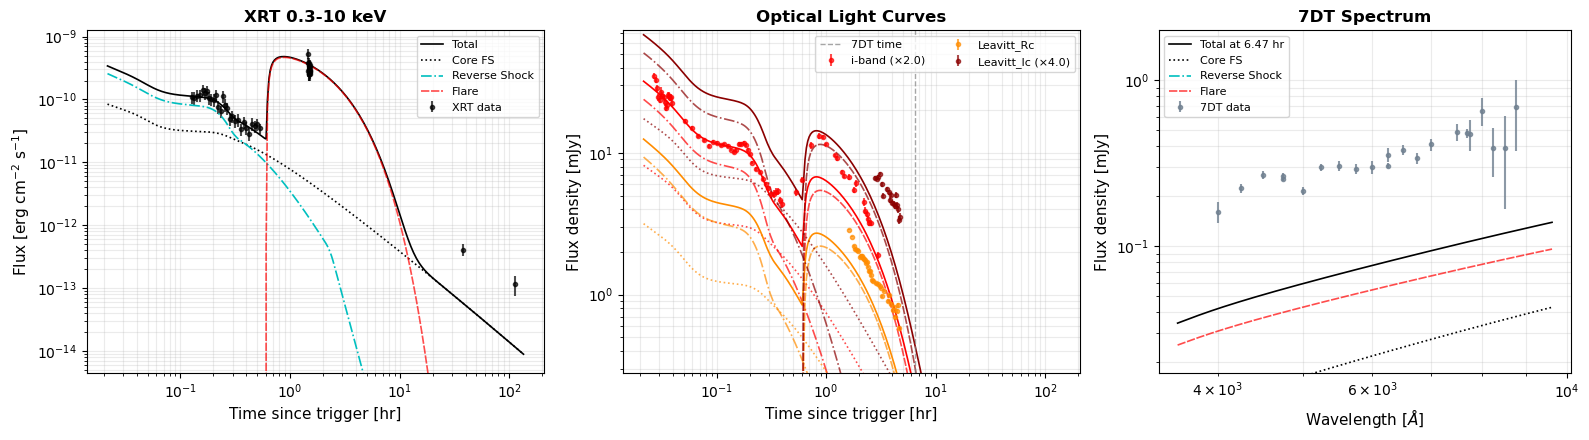

In [4]:
# 3-sigma (0.15-99.85%) posterior band, as in fit_final_model.py's bestfit_lc.png.
# posterior_dir = a saved MCMC run dir (samples.npy/log_probs.npy/labels.txt), or None for no band.
# The band comes from that run's posterior; the solid/dotted curves are still your manual params.
posterior_dir = None  # e.g. Path("/extdata01/hongyp007/projects/GRB/results/GRB251013C/final_wind_flare-norris_YYYYMMDD_HHMMSS")
band_draws = 300
band_kwargs = {}
if posterior_dir is not None:
    _draws = _posterior_draws(posterior_dir, band_draws, 42)
    if _draws is None:
        print(f"Warning: no samples.npy/log_probs.npy in {posterior_dir}; skipping 3-sigma band")
    else:
        band_kwargs = dict(posterior_draws=_draws, posterior_labels=read_labels(Path(posterior_dir) / "labels.txt"))

save_plot = False  # False: just view the figure inline, skip writing manual_lc.png to disk

outdir = Path("/home/hongyp007/hongyp/projects/GRB/results") / f"manual_{environment}_{datetime.now():%Y%m%d_%H%M%S}"

if save_plot:
    outdir.mkdir(parents=True, exist_ok=True)
    outfile = render_light_curve_figure(
        params, include_flare, include_wing, outdir / "manual_lc.png",
        mark_7dt_time=mark_7dt_time, flare_shape=flare_shape,
        **band_kwargs,
    )
    display(Image(filename=str(outfile)))
else:
    fig = render_light_curve_figure(
        params, include_flare, include_wing,
        mark_7dt_time=mark_7dt_time, flare_shape=flare_shape,
        **band_kwargs,
    )
    display(fig)
    plt.close(fig)

## Compute logL for this parameter set

Evaluate the same `log_likelihood` used by the MCMC fit (`grb.likelihood`), including the XRT spectral-index term by default (matches `fit_final_model.py`'s `--use-spectral-index` default). Data loads once in the cell below; after editing `overrides` and re-running the params/plot cells above, re-run only the last cell to get the updated logL.

Note: this logL scores *all* data, including the flare era, Leavitt and 7DT. The early-afterglow MCMC log posterior (about -88 for the representative sample) only used XRT before 3000 s and the first 40 i-band points, so the two numbers are not comparable.

In [5]:
import numpy as np
from VegasAfterglow import Scale

from grb.likelihood import log_likelihood
from grb.modeling import load_all_optical_data
from grb.spectral_index import load_xrt_spectral_index

xrt_data, optical_datasets = load_all_optical_data()
try:
    xrt_index_data = load_xrt_spectral_index()
except Exception as e:
    print(f"Warning: could not load XRT spectral index ({e}); continuing without it")
    xrt_index_data = None

In [6]:
theta = [np.log10(params[p.name]) if p.scale is Scale.LOG else params[p.name] for p in param_defs]

logL = log_likelihood(theta, param_defs, xrt_data, optical_datasets, include_flare, include_wing,
                      xrt_index_data, flare_shape)
print(f"logL = {logL:.6g}")

logL = -12448.6


## Save this parameter set (optional)

Re-running the two cells above (edit `overrides`, then re-run "build-params" and "plot") is enough to explore interactively — only run this cell if you want to keep a particular result on disk.

In [7]:
# outdir.mkdir(parents=True, exist_ok=True)

# config = {
#     "environment": environment,
#     "include_flare": include_flare,
#     "flare_shape": flare_shape,
#     "include_wing": include_wing,
#     "params": params,
#     "sources": sources,
# }
# (outdir / "params_used.json").write_text(json.dumps(config, indent=2))
# print(f"Saved: {outdir / 'params_used.json'}")

In [8]:
overrides = {
    # --- Core jet ---
    "E_iso_core": 1.1798e+52,
    "Gamma0_core": 169.355,
    "theta_c_core": 0.301029,

    # --- Circumburst medium (matches environment="ism" above) ---
    "n_ism": 146.426,

    # --- Forward shock microphysics ---
    "p": 2.10974,
    "eps_e": 0.0681586,
    "eps_B": 0.0051293,
    "tau": 22.6982,

    # --- Reverse shock ---
    "p_r": 2.7726,
    "eps_e_r": 0.2019942,
    "eps_B_r": 0.112474,

    # --- Host extinction ---
    "A_V": 0.283482,

    # --- Flare (matches flare_shape="norris" above) ---
    # "t_start_flare": 1744.89,
    # "tau_rise_flare": 533.09681,
    # "tau_decay_flare": 5567.62,
    # "A_flare": 9.94511e-10,
    # "flare_beta": 0.7522498,

    # --- Flare (flare_shape="sbpl"; no converged fit yet,
    # these are just the fit_final_model.py INITIAL_GUESS seed -- switch by
    # setting flare_shape="sbpl" above, commenting out the
    # norris block, and uncommenting this one) ---
    "t_break_flare": 1300.0,
    "alpha_rise_flare": -3.0,
    "alpha_decay_flare": 1.2,
    "smooth_flare": 1.0,
    "A_flare": 3.94511e-10,
    "flare_beta": 0.7222498,

    # --- Flare (flare_shape="gaussian"; no converged fit yet, these are just
    # the fit_final_model.py INITIAL_GUESS seed -- switch by setting
    # flare_shape="gaussian" above, commenting out the norris block, and
    # uncommenting this one) ---
    # "t_peak_flare": 3468.0,
    # "sigma_flare": 900.0,
    # "A_flare": 9.94511e-10,
    # "flare_beta": 0.7522498,
}

bounds = {p.name: (p.lower, p.upper) for p in param_defs}

params, sources = {}, {}
for p in param_defs:
    if p.name in overrides:
        value = float(overrides[p.name])
        lo, hi = bounds[p.name]
        if not (lo <= value <= hi):
            print(f"Warning: {p.name}={value:g} is outside the prior box [{lo:g}, {hi:g}]")
        params[p.name] = value
        sources[p.name] = "override"
    else:
        params[p.name] = baseline[p.name]
        sources[p.name] = "baseline"

unused = set(overrides) - {p.name for p in param_defs}
if unused:
    print(f"Warning: overrides not used by the current model config: {sorted(unused)}")

print(f"{'name':<20}{'value':>14}   source")
for p in param_defs:
    print(f"{p.name:<20}{params[p.name]:>14.6g}   {sources[p.name]}")

for w in check_physical_validity(params):
    print(f"Warning: physically invalid combination ({w}) -- plotting anyway")

name                         value   source
E_iso_core              1.1798e+52   override
Gamma0_core                169.355   override
theta_c_core              0.301029   override
A_star                    0.629797   baseline
p                          2.10974   override
eps_e                    0.0681586   override
eps_B                    0.0051293   override
tau                        22.6982   override
p_r                         2.7726   override
eps_e_r                   0.201994   override
eps_B_r                   0.112474   override
A_V                       0.283482   override
t_start_flare              1139.18   baseline
tau_rise_flare                1000   baseline
tau_decay_flare            4827.58   baseline
A_flare                3.94511e-10   override
flare_beta                 0.72225   override
xi_e                         0.505   baseline
xi_e_r                       0.505   baseline
